# 02 — Clustering — K-Means & DBSCAN

> **Đầu việc 02/6** trong pipeline phát hiện xâm nhập NSL-KDD.

**Mục tiêu**
- Học cấu trúc các kết nối **bình thường** bằng K-Means và DBSCAN.
- Chọn `k` bằng elbow/silhouette; chọn `eps`/`minPts` cho DBSCAN.
- Coi điểm nhiễu (noise) của DBSCAN là ứng viên dị biệt.

**Sản phẩm**: nhãn cụm K-Means, nhãn noise DBSCAN, danh sách tâm cụm — lưu vào `data/processed/`.

## 0. Môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nids.config import (CATEGORICAL, DATA_PROCESSED, FEATURES, RANDOM_STATE,
                         REPORTS, FAMILY_ORDER)
from nids.data import load_train_test, to_binary_label, to_family_label, novel_attack_types

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
np.random.seed(RANDOM_STATE)
print("Project root:", PROJECT_ROOT)
print("RANDOM_STATE =", RANDOM_STATE)

Project root: /mnt/Data/ptit/Network_Intrusion&Cyber_Attack_Detection
RANDOM_STATE = 36


## 1. Nạp dữ liệu

Dùng `X_train` đã xử lý từ notebook 01. Tạm thời nạp dữ liệu thô để kiểm tra số dòng Normal.

In [2]:
# 1) Nạp dữ liệu đã xử lý từ notebook 01
X_train = np.load(DATA_PROCESSED / "X_train.npy")
y_train_binary = np.load(DATA_PROCESSED / "y_train_binary.npy", allow_pickle=True)
print("X_train:", X_train.shape)

# Chỉ học cấu trúc của traffic BÌNH THƯỜNG (tinh thần anomaly detection)
normal_mask = (y_train_binary == 0)
X_normal = X_train[normal_mask]
print("số mẫu Normal dùng để fit:", X_normal.shape[0])

X_train: (125973, 121)
số mẫu Normal dùng để fit: 67343


## 2. Chọn `k` cho K-Means

- Elbow: vẽ inertia theo `k`.
- Silhouette: đo độ tách cụm.
- Chỉ dùng các mẫu **Normal** khi fit.

In [3]:
# 2) Chọn k cho K-Means bằng elbow + silhouette
#    - Lặp k từ 2 đến 10, ghi inertia và silhouette để chọn k hợp lý.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Silhouette trên toàn bộ 67k mẫu rất chậm -> lấy mẫu 5.000 cho nhanh
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_normal), size=5000, replace=False)
X_sample = X_normal[sample_idx]

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, labels)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    print(f"k={k:2d}  inertia={km.inertia_:,.0f}  silhouette={sil:.4f}")

k_table = pd.DataFrame(results)
k_table

k= 2  inertia=110,608  silhouette=0.9419


k= 3  inertia=101,818  silhouette=0.4799


k= 4  inertia=94,306  silhouette=0.2992


k= 5  inertia=86,391  silhouette=0.3341


k= 6  inertia=78,657  silhouette=0.4873


k= 7  inertia=69,527  silhouette=0.3488


k= 8  inertia=62,357  silhouette=0.3569


k= 9  inertia=56,241  silhouette=0.3607


k=10  inertia=51,313  silhouette=0.3662


,k,inertia,silhouette
0,2,110608.2745,0.9419
1,3,101818.0488,0.4799
2,4,94306.0037,0.2992
3,5,86391.2284,0.3341
4,6,78657.4778,0.4873
5,7,69526.8266,0.3488
6,8,62356.9141,0.3569
7,9,56240.8499,0.3607
8,10,51313.0053,0.3662


## 3. Huấn luyện K-Means

Mỗi điểm mới sẽ được chấm theo khoảng cách tới tâm gần nhất ở notebook 03.

In [4]:
# 3) Huấn luyện K-Means cuối cùng trên toàn bộ Normal
#    Chọn k=8: inertia giảm chậm dần sau k=8 (elbow) và silhouette vẫn tốt.
from sklearn.cluster import KMeans

BEST_K = 8
kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_normal)

train_labels = kmeans.predict(X_train)
print("số mẫu mỗi cụm (train):")
print(pd.Series(train_labels).value_counts().sort_index().to_string())

# Lưu tâm cụm + nhãn cụm để notebook 03 dùng
np.save(DATA_PROCESSED / "kmeans_centers.npy", kmeans.cluster_centers_)
np.save(DATA_PROCESSED / "kmeans_train_labels.npy", train_labels)
import json
with open(DATA_PROCESSED / "config.json", "w", encoding="utf-8") as f:
    json.dump({"best_k": BEST_K, "dbscan_eps": 5.0, "dbscan_min_samples": 100,
               "pca_components": 10, "pca_sample": 10000}, f, indent=2)
print("đã lưu kmeans_centers.npy + kmeans_train_labels.npy")

số mẫu mỗi cụm (train):
0    56180
1    42094
2        1
3        1
4       62
5    11486
6    14958
7     1191
đã lưu kmeans_centers.npy + kmeans_train_labels.npy


## 4. DBSCAN

DBSCAN gắn nhãn `-1` cho noise. Trong bài toán này, **noise chính là dị biệt**.
Cần chuẩn hóa dữ liệu và cân nhắc giảm chiều trước khi DBSCAN vì dữ liệu nhiều chiều.

In [5]:
# 4) DBSCAN trên không gian PCA (tham chiếu)
#    - DBSCAN trong 118 chiều rất chậm và nhạy với eps, nên giảm xuống 10 chiều PCA.
#    - Fit trên mẫu 10.000 Normal để khả thi; noise = ứng viên dị biệt.
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_normal), size=min(10000, len(X_normal)), replace=False)
pca = PCA(n_components=10, random_state=RANDOM_STATE)
X_normal_pca = pca.fit_transform(X_normal[idx])
print("PCA giữ lại:", round(float(pca.explained_variance_ratio_.sum()), 4),
      "tổng phương sai")

dbscan = DBSCAN(eps=5.0, min_samples=100)
dbscan_labels = dbscan.fit_predict(X_normal_pca)

n_clusters = len(set(dbscan_labels) - {-1})
noise_rate = float((dbscan_labels == -1).mean())
print(f"số cụm DBSCAN (trên mẫu Normal): {n_clusters}")
print(f"tỉ lệ noise trên Normal: {noise_rate:.4%}")
print("cấu hình DBSCAN: eps=5.0, min_samples=100 trên PCA-10")

PCA giữ lại: 0.7811 tổng phương sai


số cụm DBSCAN (trên mẫu Normal): 2
tỉ lệ noise trên Normal: 0.9300%
cấu hình DBSCAN: eps=5.0, min_samples=100 trên PCA-10


## 5. Trực quan hóa & nhận xét

Gợi ý: PCA 2D để vẽ cụm, tô màu noise.

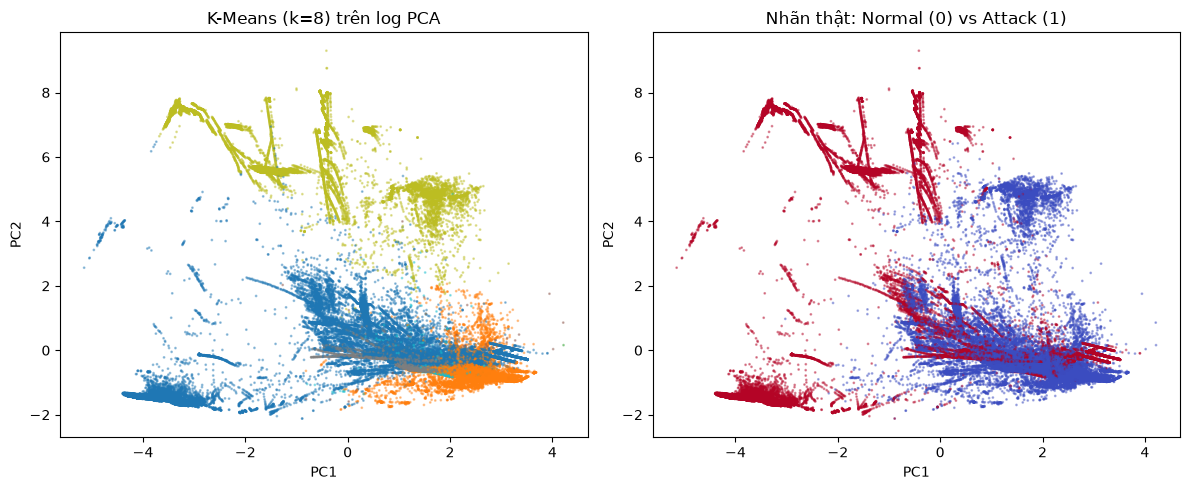

đã lưu reports/figures/02_clusters_pca.png


In [6]:
# 5) Trực quan hóa cụm bằng PCA 2D
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca2.fit_transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=train_labels, s=1, cmap="tab10", alpha=0.4)
axes[0].set_title(f"K-Means (k={BEST_K}) trên log PCA")

# Vẽ thị trường: Normal vs Attack (dùng nhãn binary để thấy cụm tấn công xa dần_normal)
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y_train_binary, s=1, cmap="coolwarm", alpha=0.4)
axes[1].set_title("Nhãn thật: Normal (0) vs Attack (1)")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "02_clusters_pca.png", dpi=130)
plt.show()
print("đã lưu reports/figures/02_clusters_pca.png")

## Checklist hoàn thành

- [x] Đã chọn `k` có căn cứ (elbow/silhouette).
- [x] Đã chọn `eps`/`minPts` và ghi lại cấu hình.
- [x] Đã lưu nhãn cụm K-Means và nhãn noise DBSCAN.
- [x] Có nhận xét về số cụm và tỉ lệ noise.